# From clusters to interpretable topics

In this notebook, we use sentence embeddings to cluster then and then built on this clustering to create interpretable topics.

## Python setup

#### Colab

If you want to run this notebook in Google Colab, click the badge below.
It will open a copy of this notebook in Colab, where you can run the code without installing anything on your own computer.

<br>
<a target="_blank" href="https://colab.research.google.com/github/haukelicht/dia_text_analysis/blob/main/notebooks/04-topic_modeling/clustering_and_bertopic.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

**_Note:_** Always run the cell below – also if you run this notebook on your Laptop and not on Colab.

In [1]:
# check if on colab
COLAB = True
try:
    import google.colab
except:
    COLAB = False

if COLAB:
    # shallow clone of current state of main branch 
    !git clone --branch main --single-branch --depth 1 --filter=blob:none https://github.com/haukelicht/dia_text_analysis.git

    %cd dia_text_analysis/notebooks/04-topic_modeling
    %pip install -q -U umap-learn~=0.5.12 hdbscan==0.8.44 sentence-transformers~=6.0.1 bertopic==0.17.4        
    
    import sys
    sys.path.insert(0, "dia_text_analysis/notebooks/04-topic_modeling")


Now, run this cell:

In [2]:
from pathlib import Path
import pandas as pd

from sentence_transformers import SentenceTransformer

from utils import (
    display_coordinates,
    plot_clusters,
    load_prepared_embeddings,
    get_bertopic_model,
    topic_overview,
    representative_documents
)

from IPython.display import HTML, display
print_html = lambda x, **kwargs: display(HTML(x.to_html(**kwargs)))

In [3]:
project_root = Path('../..').resolve()
DATA_DIR = project_root / "data" / "examples" / "cap"
RESULTS = project_root / "output" / "session04"
RESULTS.mkdir(exist_ok=True, parents=True)

## 1. Clustering

We first use only the 30 example sentences you have manually clustered for Exercise 1 in the slides for session 4 (Block 2, Day 1).

In [4]:
sentences_fp = DATA_DIR / "example_sentences.csv"
sentences = pd.read_csv(sentences_fp, usecols=["id", "text"])
sentences.head()

,id,text
0,s01,The gravest threat we face — nuclear terrorism...
1,s02,Our diplomacy has helped to halt North Korea's...
2,s03,We must show determined leadership to end the ...
3,s04,"Over the past three decades, America has signe..."
4,s05,The next Republican president will protect our...


### Step 1: Embed the sentences

First, we embed the 30 sentences:

In [5]:
model_id = 'sentence-transformers/all-MiniLM-L6-v2'
embedding_model = SentenceTransformer(model_id)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [6]:
texts = sentences["text"].tolist()
embeddings = embedding_model.encode(texts, normalize_embeddings=True)

### Step 2: Dimensionality reduction



Now, we reduce the sentences' embeddings matrix from a 384-dimensional representation to a 10-dimensional representation.
We do this because clustering algorithms work better with fewer dimensions.

**_Note:_** Reduction changes the representation and can affect grouping; we do not derive the algorithm here.

<!-- **_Note:_**: A **separate 2D projection** will be used only for display. -->

In [7]:
from umap import UMAP

# create the class instance
reducer = UMAP(
    n_components=10, 
    n_neighbors=15,
    min_dist=0.0,
    metric='cosine',
    random_state=42,
    n_jobs=1
)

# apply the dimensionality reduction to the embeddings
reduced_embeddings = reducer.fit_transform(embeddings)

# inspect the shape of the reduced embeddings
reduced_embeddings.shape # sentences x 10 dimensions

(30, 10)

The supplied reduction uses UMAP with 10 components, 15 neighbors, cosine input distance, minimum distance 0 and seed 42.

Here is what the paramters mean:

- `n_components=10` specifies the number of dimensions to reduce to.
- `n_neighbors=15` specifies the number of neighbors to consider when estimating the manifold structure of the data.
- `min_dist=0` specifies the minimum distance between points in the low-dimensional representation.
- `metric="cosine"` specifies the distance metric to use when computing distances between points in the high-dimensional space.
- `random_state=42` specifies the random seed to use for reproducibility (requires `n_jobs=1`).

**_Note:_** These are documented preparation choices rather than parameters you need to optimize.

### Step 3: Clustering with HDBSCAN

Let's cluster the reduced embeddings using HDBSCAN.
HDBSCAN is a density-based clustering algorithm that can find clusters of varying shapes and sizes, and it can also identify noise points that do not belong to any cluster.

We first create a `clusterer` instance from `HDBSCAN`:

In [8]:
from hdbscan import HDBSCAN

clusterer = HDBSCAN(
    min_cluster_size=8, min_samples=2,
    metric='euclidean',
    cluster_selection_method='eom',
    approx_min_span_tree=False,
    core_dist_n_jobs=1
)

Here is what the paramters mean:

- **`min_samples=2`**: This parameter specifies the minimum number of samples in a neighborhood for a point to be considered a core point. A core point is a point that has at least `min_samples` points (including itself) within its neighborhood. In this case, we set it to 2, meaning that a point must have at least one other point in its neighborhood to be considered a core point.
- **`min_cluster_size=2`**: This parameter specifies the minimum size of a cluster. A cluster must have at least `min_cluster_size` points to be considered a valid cluster. In this case, we set it to 2, meaning that a cluster must have at least two points to be considered a valid cluster.
- **`metric='euclidean'`**: This parameter specifies the distance metric to be used for calculating distances between points. In this case, we use the Euclidean distance metric, which is the straight-line distance between two points in Euclidean space.
- **`cluster_selection_method='eom'`**: This parameter specifies the method used for selecting clusters from the hierarchical clustering tree. In this case, we use the "excess of mass" (EOM) method, which selects clusters based on the excess of mass in the hierarchical tree.

Now we can use the 10-dimensional representation of the sentences to cluster them with HDBSCAN.
This will **assign each sentence to a cluster group**.
We store this cluster assignment in `clusters`:


In [9]:
clusters = clusterer.fit_predict(reduced_embeddings)

In [10]:
print(clusters)
sentences['cluster'] = clusters

[0 0 0 1 0 2 0 2 1 2 0 1 1 2 2 0 1 2 2 2 0 2 1 1 1 1 0 2 1 0]


**_Note:_** HDBSCAN can leave sentences unassigned (cluster ID `-1`); that does not mean bad data. Group numbers have no substantive order.

Let's **visualize** the clusters in a reduced 2D projection of the embeddings:

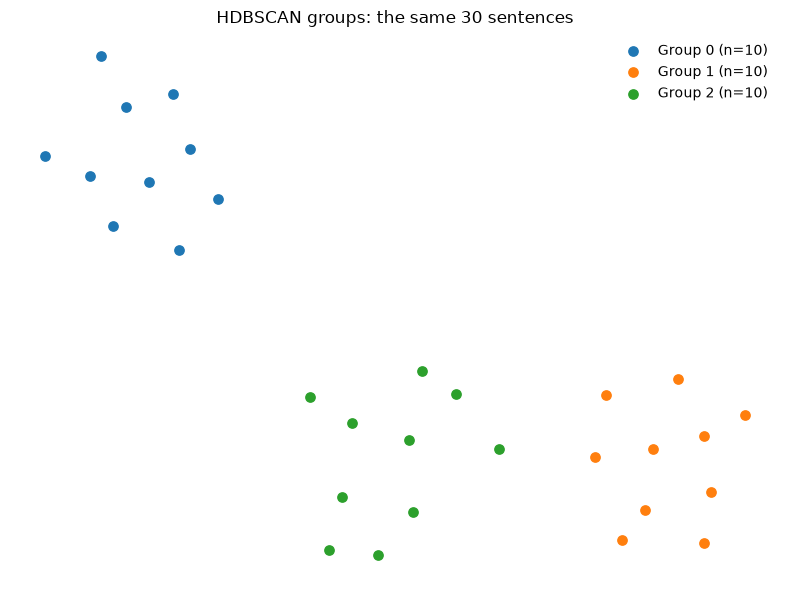

In [11]:
xy_coordinates = display_coordinates(embeddings)
plot_clusters(xy_coordinates, clusters, title="HDBSCAN groups: the same 30 sentences")

**_Note:_** This map is a display of assignments fitted in 10D. Its gaps and orientation are not precise measurements of topic differences. No reference categories were supplied to the model.

### Exercise 2: Compare your manually built cluster to the model solution

Compare sentences' cluster memberships with your original solution for Exercise 3.
A different number of groups is an invitation to examine the grouping rule, not evidence that the computer is right.

In [12]:
# add cluster assignments to the sentences data frame
sentences["cluster_group"] = clusters
sentences["cluster_group"].value_counts().sort_index()

cluster_group
0    10
1    10
2    10
Name: count, dtype: int64

In [13]:
# TODO: specify the IDs of the sentences you manually grouped into a cluster
my_cluster_ids = [] # e.g., "s01", "s03", etc.
# my_cluster_ids = ["s01", "s02", "s03", "s05", "s07", "s11"] # nuclear
my_cluster_ids = ["s04", "s09", "s12", "s13", "s17"] # trade

In [14]:
subset = sentences.id.isin(my_cluster_ids)
sentences[subset]

,id,text,cluster,cluster_group
3,s04,"Over the past three decades, America has signe...",1,1
8,s09,New trade agreements must protect internationa...,1,1
11,s12,We believe any new trade agreements must inclu...,1,1
12,s13,We will work with Canada and Mexico to amend t...,1,1
16,s17,"We encourage multilateral, regional, and bilat...",1,1


## 2. Topic modeling

Clusters are interesting, but they are hard to interpret.
We can add a **topic description** to each cluster with BERTopic.

We already have embeddings, a supplied reduction step and a grouping rule. 
**BERTopic adds a textual description**: combine the words of the texts within each group and compute characteristic terms with c-TF-IDF.
Words frequent in a group but less common across the grouped corpus can help describe it.
This is a bag-of-words description **after clustering**, not the representation that created the groups.

In [15]:
# NOTE: we re-use the `texts` and `embeddings` objects created previusly
# sentences = pd.read_csv(DATA_DIR / "example_sentences.csv")
# texts = sentences["text"].tolist()
# embeddings = embedding_model.encode(texts, convert_to_numpy=True, normalize_embeddings=True)

We use the helper function `get_bertopic_model` (defined in [utils.py](utils.py)) to create a BERTopic model with the same reduction and grouping as above.
This returns a **`BERTmodel`** object we call `topic_model` here.

In [16]:
topic_model = get_bertopic_model(embedding_model, minimum_group_size=8)

Now we can "fit" it to the 30 sentences and their embeddings.
This returns a list of **topic numbers** for each sentence, which we store in `topics`, and document--topic probabilities, which we store in `probs`:

In [17]:
topics, probs = topic_model.fit_transform(texts, embeddings)

# add topic assignments to the sentences data frame
sentences["topic"] = topics

The topic assignment is the same as the cluster assignment we created previously:

In [18]:
# show that each documents' topic assignment is the same as the cluster assignment we created previously
print((topics == clusters).all())

True


This is because BERTopic literally uses the same UMAP reduction and HDBSCN clustering workflow as we did above.

The **_difference_** is that BERTopic adds a **textual description** of each group.

First, **topics' most distinctive terms**:

In [19]:
print_html(topic_overview(topic_model))

,Topic,Count,Distinctive terms
0,0,10,"[north, strong, world, implement, leadership, america, programs, global]"
1,1,10,"[american, support, work, protect, agreement, believe, strong, north]"
2,2,10,"[development, national, democrats, believe, world, countries, decades, streamlined]"


## 3. Topic interpretation

To interpret a topic, we consider the terms **together with** the representative documents before proposing a label and a one-sentence definition.

### Example: Topic `0` 

In [20]:
topic_nr = 0
print_html(pd.DataFrame(topic_model.get_topic(topic_nr), columns=["term", "c-TF-IDF weight"]))
print_html(representative_documents(topic_model, topic_nr))

,term,c-TF-IDF weight
0,north,0.253132
1,strong,0.186154
2,world,0.168754
3,implement,0.121552
4,leadership,0.121552
5,america,0.121552
6,programs,0.121552
7,global,0.121552


,text
0,We must show determined leadership to end the nuclear weapons program in North Korea and prevent the development of nuclear weapons in places like Iran.
1,"We will maintain a strong and reliable deterrent as long as nuclear weapons exist, but America will be safer in a world that is reducing reliance on nuclear weapons and ultimately eliminates all of them."
2,Our diplomacy has helped to halt North Korea's push for nuclear weapons.


In [21]:
print_html(sentences[sentences["topic"] == topic_nr][["id", "text"]])

,id,text
0,s01,The gravest threat we face — nuclear terrorism — demands a comprehensive strategy for reducing the world's nuclear stockpiles and preventing proliferation.
1,s02,Our diplomacy has helped to halt North Korea's push for nuclear weapons.
2,s03,We must show determined leadership to end the nuclear weapons program in North Korea and prevent the development of nuclear weapons in places like Iran.
4,s05,The next Republican president will protect our nuclear secrets and aggressively implement a sweeping reorganization of our nuclear weapons program.
6,s07,"We will maintain a strong and reliable deterrent as long as nuclear weapons exist, but America will be safer in a world that is reducing reliance on nuclear weapons and ultimately eliminates all of them."
10,s11,A nuclear-armed Iran is an unacceptable risk to us and our allies.
15,s16,"We will work to maintain a strong, credible deterrent while reducing our overreliance and excessive expenditure on nuclear weapons."
20,s21,"We support the nuclear agreement with Iran because, as it is vigorously enforced and implemented, it verifiably cuts off all of Iran's pathways to a bomb without resorting to war."
26,s27,"The U.S. will continue to demand the complete, verifiable, and irreversible dismantlement of North Korea's nuclear weapons programs with a full accounting of its proliferation activities."
29,s30,Democrats will lower regional-and global-threats by reinforcing nuclear arms control.


**Example interpretation**:

- *label:* Strategic foreign assistance and development 
- *definition:* Statements presenting foreign aid and development programs as instruments for promoting international development, security, and U.S. interests.
- *Complicating member:* The following cases highlight the limits of this interpretation
    - "Decades of massive development assistance have failed to spur economic growth in the poorest countries.": This example additionally introduces skepticism about whether aid actually produces development.
- *Competing label:* "Foreign-aid policy and reform" could be a competing label, but it is less specific than the chosen label.

### Exercise 4

**TODO**: Choose one of the other topics (`1` or `2`) and propose a label and one-sentence definition. Then check additional members to see if they support your interpretation.